In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style='whitegrid')

# Consistent randomness
RANDOM_SEED = 123
np.random.seed(RANDOM_SEED)

%matplotlib inline

DATA_PATH = "Company_Data.csv"

In [2]:
def accuracy(y_true, y_pred):
    return np.mean(np.array(y_true) == np.array(y_pred))

def precision(y_true, y_pred):
    y_true = np.array(y_true); y_pred = np.array(y_pred)
    tp = np.sum((y_true==1)&(y_pred==1))
    fp = np.sum((y_true==0)&(y_pred==1))
    return tp / (tp + fp + 1e-9)

def recall(y_true, y_pred):
    y_true = np.array(y_true); y_pred = np.array(y_pred)
    tp = np.sum((y_true==1)&(y_pred==1))
    fn = np.sum((y_true==1)&(y_pred==0))
    return tp / (tp + fn + 1e-9)

def f1_score(y_true, y_pred):
    p = precision(y_true, y_pred)
    r = recall(y_true, y_pred)
    return 2 * p * r / (p + r + 1e-9)

def plot_confusion_matrix(y_true, y_pred, title=None):
    cm = np.zeros((2,2), dtype=int)
    for t,p in zip(y_true, y_pred):
        cm[int(t), int(p)] += 1
    
    plt.figure(figsize=(4,3))
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', cbar=False,
        xticklabels=['Low', 'High'], yticklabels=['Low', 'High']
    )
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    if title:
        plt.title(title)
    plt.show()


In [3]:
# Load data
df = pd.read_csv(DATA_PATH)

if 'Sales' not in df.columns:
    raise ValueError("The dataset must contain a 'Sales' column.")

df = df.copy()

# Create binary target from median
median_sales = df["Sales"].median()
df["HighSales"] = (df["Sales"] >= median_sales).astype(int)

# Encode categoricals
cat_cols = df.select_dtypes(include=["object", "category"]).columns
for c in cat_cols:
    df[c] = df[c].astype("category").cat.codes

FEATURES = [c for c in df.columns if c not in ["Sales", "HighSales"]]

X = df[FEATURES].reset_index(drop=True)
y = df["HighSales"].reset_index(drop=True).astype(int)

print("Shape:", df.shape)
print("Features:", FEATURES)
print("Target distribution:")
print(y.value_counts())
df.head()

Shape: (400, 12)
Features: ['CompPrice', 'Income', 'Advertising', 'Population', 'Price', 'ShelveLoc', 'Age', 'Education', 'Urban', 'US']
Target distribution:
HighSales
1    201
0    199
Name: count, dtype: int64


,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US,HighSales
0,9.50,138,73,11,276,120,0,42,17,1,1,1
1,11.22,111,48,16,260,83,1,65,10,1,1,1
2,10.06,113,35,10,269,80,2,59,12,1,1,1
3,7.40,117,100,4,466,97,2,55,14,1,1,0
4,4.15,141,64,3,340,128,0,38,13,1,0,0


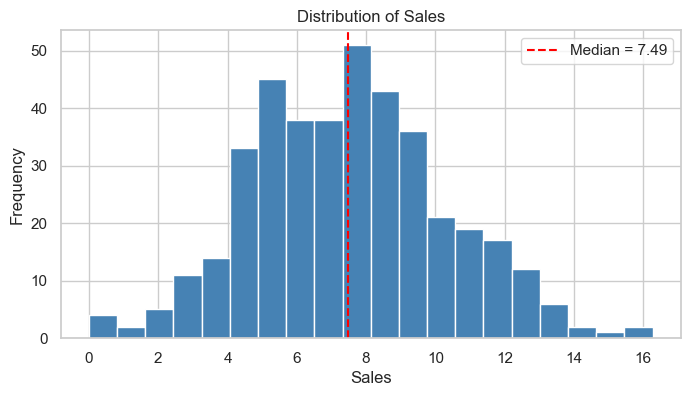

Counts for HighSales:
Low Sales (0): 199
High Sales (1): 201


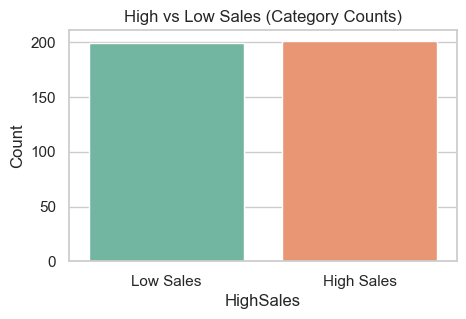

In [4]:
# --- Sales distribution with median ---
plt.figure(figsize=(8,4))
plt.hist(df['Sales'], bins=20, color='steelblue')
plt.axvline(median_sales, color='red', linestyle='--', label=f'Median = {median_sales:.2f}')
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.title("Distribution of Sales")
plt.legend()
plt.show()

# --- Category counts for HighSales ---
counts = df['HighSales'].value_counts().sort_index()
print("Counts for HighSales:")
print("Low Sales (0):", counts[0])
print("High Sales (1):", counts[1])

plt.figure(figsize=(5,3))
sns.countplot(x=df["HighSales"], palette="Set2")
plt.xticks([0,1], ["Low Sales", "High Sales"])
plt.ylabel("Count")
plt.title("High vs Low Sales (Category Counts)")
plt.show()


In [5]:
rs = np.random.RandomState(RANDOM_SEED)
indices = rs.permutation(len(X))

n = len(X)
n_train = int(0.60 * n)
n_val   = int(0.15 * n)
n_test  = n - n_train - n_val

train_idx = indices[:n_train]
val_idx   = indices[n_train:n_train+n_val]
test_idx  = indices[n_train+n_val:]

X_train = X.iloc[train_idx].reset_index(drop=True)
X_val   = X.iloc[val_idx].reset_index(drop=True)
X_test  = X.iloc[test_idx].reset_index(drop=True)

y_train = y.iloc[train_idx].reset_index(drop=True).values
y_val   = y.iloc[val_idx].reset_index(drop=True).values
y_test  = y.iloc[test_idx].reset_index(drop=True).values

print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)

print("Class distribution across splits:")
print("Train:", np.bincount(y_train))
print("Val:  ", np.bincount(y_val))
print("Test: ", np.bincount(y_test))


Train: (240, 10) Val: (60, 10) Test: (100, 10)
Class distribution across splits:
Train: [112 128]
Val:   [38 22]
Test:  [49 51]


In [6]:
# ----- Impurity Measures -----

def entropy(arr):
    arr = np.array(arr)
    if arr.size == 0:
        return 0.0
    vals, cnts = np.unique(arr, return_counts=True)
    probs = cnts / cnts.sum()
    return -np.sum(probs * np.log2(probs + 1e-9))


# ----- Utility for generating candidate split thresholds -----

def candidate_thresholds(col):
    vals = np.unique(col)
    if vals.size <= 1:
        return []
    vals = np.sort(vals)
    mids = (vals[:-1] + vals[1:]) / 2.0
    return mids.tolist()


# ----- Perform binary split -----

def split_indices(col, thr):
    left = np.nonzero(col <= thr)[0]
    right = np.nonzero(col > thr)[0]
    return left, right


# ----- Information gain -----

def information_gain(parent_y, left_y, right_y, impurity_func=entropy):
    if len(parent_y) == 0:
        return 0.0
    wL = len(left_y) / len(parent_y)
    wR = len(right_y) / len(parent_y)
    return impurity_func(parent_y) - (
        wL * impurity_func(left_y) + wR * impurity_func(right_y)
    )


In [7]:
class Node:
    def __init__(self, feature=None, threshold=None, left=None, right=None, value=None, gain=0.0):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value
        self.gain = gain


def best_split(X_df, y_arr, impurity_func=entropy, max_features=None, rnd_state=None):
    best_feature = None
    best_threshold = None
    best_gain = -np.inf

    features = list(X_df.columns)
    n_features = len(features)

    # Optional feature subsampling (for RF later)
    if max_features is not None and 1 <= max_features < n_features:
        if rnd_state is None:
            rnd_state = np.random.RandomState(RANDOM_SEED)
        features = list(rnd_state.choice(features, size=max_features, replace=False))

    for feature in features:
        col = X_df[feature].values
        for thr in candidate_thresholds(col):
            li, ri = split_indices(col, thr)
            if len(li) == 0 or len(ri) == 0:
                continue

            gain = information_gain(y_arr, y_arr[li], y_arr[ri], impurity_func)
            if gain > best_gain + 1e-12:
                best_gain = gain
                best_feature = feature
                best_threshold = thr
            # Tie-break by feature order for determinism
            elif abs(gain - best_gain) <= 1e-12 and best_feature is not None:
                if features.index(feature) < features.index(best_feature):
                    best_feature = feature
                    best_threshold = thr

    return best_feature, best_threshold, best_gain


In [8]:
def build_tree(X_df, y_arr, depth=0, max_depth=5, min_samples_split=2,
               impurity_func=entropy, max_features=None, rnd_state=None):

    if X_df.shape[0] == 0:
        return Node(value=0)

    unique_vals = np.unique(y_arr)
    if len(unique_vals) == 1 or depth >= max_depth or len(y_arr) < min_samples_split:
        counts = np.bincount(y_arr)
        return Node(value=int(np.argmax(counts)))

    feature, threshold, gain = best_split(X_df, y_arr, impurity_func, max_features, rnd_state)

    if feature is None or gain <= 1e-12:
        counts = np.bincount(y_arr)
        return Node(value=int(np.argmax(counts)))

    li, ri = split_indices(X_df[feature].values, threshold)

    left = build_tree(
        X_df.iloc[li].reset_index(drop=True), y_arr[li],
        depth + 1, max_depth, min_samples_split,
        impurity_func, max_features, rnd_state
    )

    right = build_tree(
        X_df.iloc[ri].reset_index(drop=True), y_arr[ri],
        depth + 1, max_depth, min_samples_split,
        impurity_func, max_features, rnd_state
    )

    return Node(feature=feature, threshold=threshold, left=left, right=right, gain=gain)


def predict_one(node, row):
    while node.value is None:
        if row[node.feature] <= node.threshold:
            node = node.left
        else:
            node = node.right
    return int(node.value)


def predict(tree, X_df):
    return np.array([predict_one(tree, row) for _, row in X_df.iterrows()])


In [9]:
def count_nodes(node):
    if node is None:
        return 0
    if node.value is not None:
        return 1
    return 1 + count_nodes(node.left) + count_nodes(node.right)

def count_leaves(node):
    if node is None:
        return 0
    if node.value is not None:
        return 1
    return count_leaves(node.left) + count_leaves(node.right)

def tree_max_depth(node):
    if node is None or node.value is not None:
        return 0
    return 1 + max(tree_max_depth(node.left), tree_max_depth(node.right))

def count_splits(node, acc=None):
    if acc is None:
        acc = {}
    if node is None:
        return acc
    if node.feature is not None:
        acc[node.feature] = acc.get(node.feature, 0) + 1
        count_splits(node.left, acc)
        count_splits(node.right, acc)
    return acc



TASK 1: Baseline Decision Tree
{'Train Accuracy': 0.8958333333333334, 'Test Accuracy': 0.67, 'Precision': 0.6730769230639794, 'Recall': 0.6862745097904652, 'F1-Score': 0.6796116499722877}
{'Total Nodes': 45, 'Leaf Nodes': 23, 'Max Depth': 6}


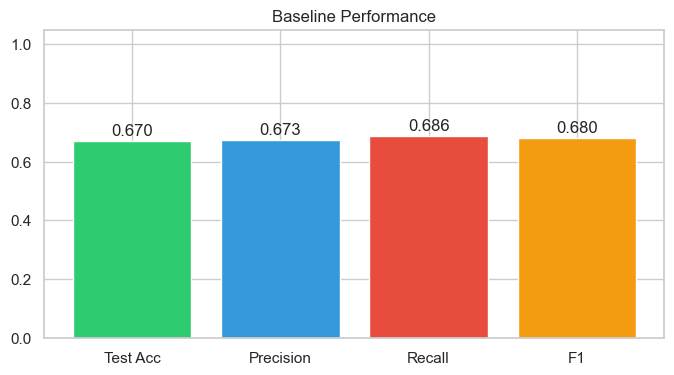

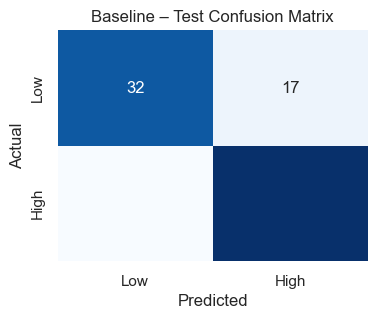

In [10]:
print("\nTASK 1: Baseline Decision Tree")

baseline_tree = build_tree(
    X_train, y_train,
    max_depth=6,
    min_samples_split=5,
    rnd_state=np.random.RandomState(RANDOM_SEED)
)

y_pred_train = predict(baseline_tree, X_train)
y_pred_test  = predict(baseline_tree, X_test)

metrics_baseline = {
    "Train Accuracy": accuracy(y_train, y_pred_train),
    "Test Accuracy": accuracy(y_test, y_pred_test),
    "Precision": precision(y_test, y_pred_test),
    "Recall": recall(y_test, y_pred_test),
    "F1-Score": f1_score(y_test, y_pred_test)
}

tree_stats = {
    "Total Nodes": count_nodes(baseline_tree),
    "Leaf Nodes": count_leaves(baseline_tree),
    "Max Depth": tree_max_depth(baseline_tree)
}

print(metrics_baseline)
print(tree_stats)

plt.figure(figsize=(8,4))
vals = [metrics_baseline["Test Accuracy"], metrics_baseline["Precision"],
        metrics_baseline["Recall"], metrics_baseline["F1-Score"]]
labels = ["Test Acc", "Precision", "Recall", "F1"]

bars = plt.bar(labels, vals, color=["#2ecc71","#3498db","#e74c3c","#f39c12"])
plt.ylim(0,1.05)
for b,v in zip(bars,vals):
    plt.text(b.get_x()+b.get_width()/2, v+0.02, f"{v:.3f}", ha="center")
plt.title("Baseline Performance")
plt.show()

plot_confusion_matrix(y_test, y_pred_test, "Baseline – Test Confusion Matrix")



TASK 2: Feature Importance


,Feature,Split_Count,Gini_Importance,Abs_Correlation,Norm_Split,Norm_Gain,Norm_Corr,Composite_Score
0,Population,5,1.243077,0.064853,1.0,1.000000,0.171849,0.834370
1,Price,4,0.888367,0.377387,0.8,0.714652,1.000000,0.805861
2,Income,3,0.904753,0.126266,0.6,0.727833,0.334579,0.598049
3,Advertising,2,0.722462,0.246437,0.4,0.581188,0.653009,0.523077
4,CompPrice,3,0.610075,0.046041,0.6,0.490778,0.122000,0.460711
5,Age,2,0.531962,0.193087,0.4,0.427940,0.511642,0.433504
6,ShelveLoc,2,0.251734,0.109274,0.4,0.202509,0.289556,0.298915
7,Education,1,0.099213,0.026555,0.2,0.079812,0.070365,0.125998
8,US,0,0.000000,0.139549,0.0,0.000000,0.369776,0.073955
9,Urban,0,0.000000,0.040622,0.0,0.000000,0.107639,0.021528


Top 3 features: ['Population', 'Price', 'Income']


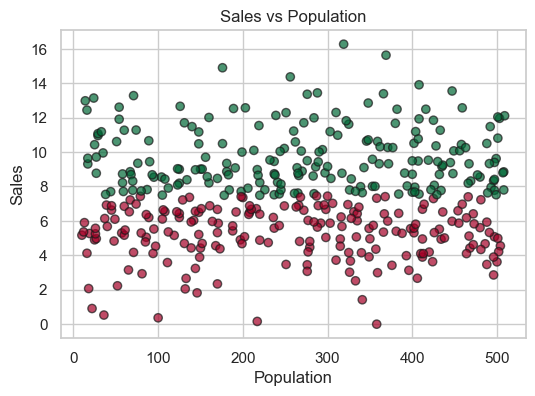

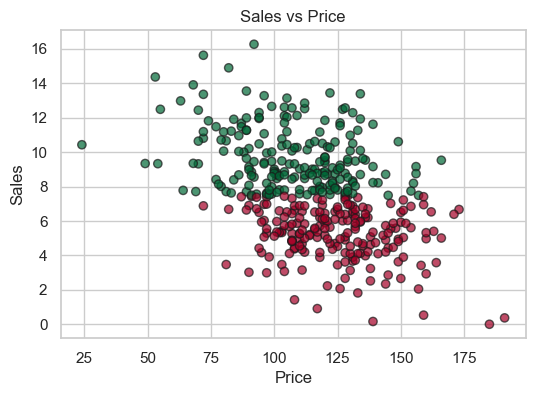

In [11]:
print("\nTASK 2: Feature Importance")

split_counts = count_splits(baseline_tree)

# Collect gains for each feature
def collect_gains(node, acc=None):
    if acc is None:
        acc = {}
    if node and node.feature is not None:
        acc[node.feature] = acc.get(node.feature, 0) + node.gain
        collect_gains(node.left, acc)
        collect_gains(node.right, acc)
    return acc

gain_map = collect_gains(baseline_tree)

corrs = df[FEATURES + ["HighSales"]].corr()["HighSales"].abs().drop("HighSales").to_dict()

# Normalize to build composite score
split_max = max(split_counts.values()) if split_counts else 1
gain_max  = max(gain_map.values()) if gain_map else 1e-9
corr_max  = max(corrs.values()) if corrs else 1e-9

rows = []
for f in FEATURES:
    rows.append({
        "Feature": f,
        "Split_Count": split_counts.get(f,0),
        "Gini_Importance": gain_map.get(f,0.0),
        "Abs_Correlation": corrs.get(f,0.0),
        "Norm_Split": split_counts.get(f,0)/split_max,
        "Norm_Gain": gain_map.get(f,0.0)/gain_max,
        "Norm_Corr": corrs.get(f,0.0)/corr_max
    })

importance_df = pd.DataFrame(rows)
importance_df["Composite_Score"] = (
    0.4*importance_df["Norm_Split"] +
    0.4*importance_df["Norm_Gain"] +
    0.2*importance_df["Norm_Corr"]
)

importance_df = importance_df.sort_values("Composite_Score", ascending=False).reset_index(drop=True)
display(importance_df.head(10))

top3 = importance_df["Feature"].head(3).tolist()
print("Top 3 features:", top3)

# Scatter for top2
for f in top3[:2]:
    plt.figure(figsize=(6,4))
    plt.scatter(df[f], df["Sales"], c=df["HighSales"], cmap="RdYlGn", alpha=0.7, edgecolor="k")
    plt.title(f"Sales vs {f}")
    plt.xlabel(f)
    plt.ylabel("Sales")
    plt.show()



TASK 3A: Pre-Pruning (Validation-based grid search)


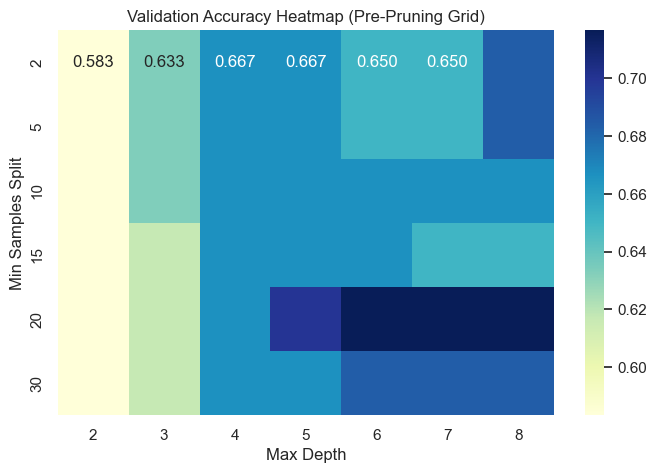

Selected pre-pruning parameters: (6, 20)
Pre-Pruned Metrics: {'Test Accuracy': 0.65, 'Precision': 0.6538461538335799, 'Recall': 0.6666666666535949, 'F1-Score': 0.6601941742445094}
Pre-Pruned Tree Stats: {'Total Nodes': 31, 'Leaf Nodes': 16, 'Max Depth': 6}


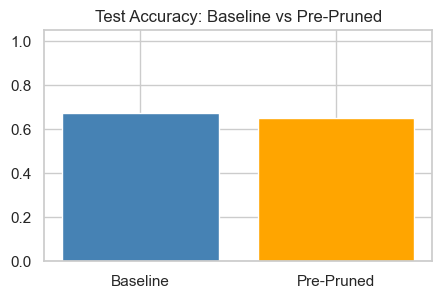

In [12]:
# -------------------------
# TASK 3A: Pre-Pruning Grid Search
# -------------------------

print("\nTASK 3A: Pre-Pruning (Validation-based grid search)")

grid_results = []

# Try a reasonable range of depths and minimum splits
depth_values = [2, 3, 4, 5, 6, 7, 8]
minsplit_values = [2, 5, 10, 15, 20, 30]

for max_d in depth_values:
    for min_s in minsplit_values:
        # Build tree on the training set
        t = build_tree(
            X_train, y_train,
            max_depth=max_d,
            min_samples_split=min_s,
            rnd_state=np.random.RandomState(RANDOM_SEED)
        )
        
        # Evaluate only on validation for model selection
        val_pred = predict(t, X_val)
        test_pred = predict(t, X_test)  # recorded but not used for choosing hyperparams
        
        grid_results.append({
            "max_depth": max_d,
            "min_samples_split": min_s,
            "val_acc": accuracy(y_val, val_pred),
            "test_acc": accuracy(y_test, test_pred),
            "nodes": count_nodes(t),
            "depth": tree_max_depth(t)
        })

# Put everything into a DataFrame
res_df = pd.DataFrame(grid_results)

# Heatmap of validation accuracy
pivot = res_df.pivot(index="min_samples_split", columns="max_depth", values="val_acc")

plt.figure(figsize=(8,5))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="YlGnBu")
plt.title("Validation Accuracy Heatmap (Pre-Pruning Grid)")
plt.xlabel("Max Depth")
plt.ylabel("Min Samples Split")
plt.show()

# Choose strongest model based on validation accuracy
# Tie-breaker: fewer nodes (simpler model)
best_row = res_df.sort_values(["val_acc", "nodes"], ascending=[False, True]).iloc[0]
best_max_d  = int(best_row["max_depth"])
best_min_s  = int(best_row["min_samples_split"])

print("Selected pre-pruning parameters:", (best_max_d, best_min_s))

# Build final pre-pruned tree
pre_pruned_tree = build_tree(
    X_train, y_train,
    max_depth=best_max_d,
    min_samples_split=best_min_s,
    rnd_state=np.random.RandomState(RANDOM_SEED)
)

pre_pred_test = predict(pre_pruned_tree, X_test)

metrics_pre_pruned = {
    "Test Accuracy": accuracy(y_test, pre_pred_test),
    "Precision": precision(y_test, pre_pred_test),
    "Recall": recall(y_test, pre_pred_test),
    "F1-Score": f1_score(y_test, pre_pred_test)
}

pre_pruned_stats = {
    "Total Nodes": count_nodes(pre_pruned_tree),
    "Leaf Nodes": count_leaves(pre_pruned_tree),
    "Max Depth": tree_max_depth(pre_pruned_tree)
}

print("Pre-Pruned Metrics:", metrics_pre_pruned)
print("Pre-Pruned Tree Stats:", pre_pruned_stats)

# Small visualization: Accuracy comparison
plt.figure(figsize=(5,3))
plt.bar(["Baseline", "Pre-Pruned"],
        [metrics_baseline["Test Accuracy"], metrics_pre_pruned["Test Accuracy"]],
        color=["steelblue", "orange"])
plt.ylim(0,1.05)
plt.title("Test Accuracy: Baseline vs Pre-Pruned")
plt.show()



TASK 3B: Reduced-Error Post-Pruning
Validation accuracy before pruning: 0.6333333333333333
Internal nodes to evaluate for pruning: 44
Nodes pruned: 26
Validation accuracy after pruning: 0.8333333333333334
Post-Pruned Metrics: {'Test Accuracy': 0.56, 'Precision': 0.5999999999828572, 'Recall': 0.41176470587427916, 'F1-Score': 0.488372092529205}
Post-Pruned Tree Stats: {'Total Nodes': 27, 'Leaf Nodes': 14, 'Max Depth': 8}


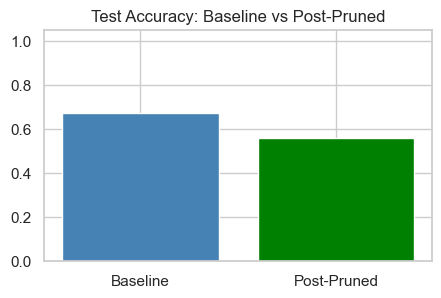

In [13]:
# -------------------------
# TASK 3B: Reduced-Error Post-Pruning
# -------------------------

print("\nTASK 3B: Reduced-Error Post-Pruning")

# Step 1: Grow a deep tree first (overfitted model)
deep_tree = build_tree(
    X_train, y_train,
    max_depth=100,               # intentionally large
    min_samples_split=2,
    rnd_state=np.random.RandomState(RANDOM_SEED)
)

# Helper: collect internal (non-leaf) nodes in postorder
def collect_internal_nodes(node, out_list):
    if node is None:
        return
    collect_internal_nodes(node.left, out_list)
    collect_internal_nodes(node.right, out_list)
    if node.feature is not None:
        out_list.append(node)

# Helper: find which rows reach a particular node
def rows_reaching(node, root, X_df):
    mask = []
    for _, row in X_df.iterrows():
        curr = root
        reached = False
        while curr is not None and curr.value is None:
            if curr is node:
                reached = True
                break
            if row[curr.feature] <= curr.threshold:
                curr = curr.left
            else:
                curr = curr.right
        if curr is node:
            reached = True
        mask.append(reached)
    return np.array(mask, dtype=bool)


# Step 2: Compute validation accuracy before pruning
before_val_pred = predict(deep_tree, X_val)
before_val_acc = accuracy(y_val, before_val_pred)
print("Validation accuracy before pruning:", before_val_acc)

# Step 3: Collect nodes to consider
internal_nodes = []
collect_internal_nodes(deep_tree, internal_nodes)
print("Internal nodes to evaluate for pruning:", len(internal_nodes))

current_val_acc = before_val_acc
pruned_count = 0

# Step 4: Try pruning each internal node
for node in internal_nodes:
    mask = rows_reaching(node, deep_tree, X_val)
    if mask.sum() == 0:
        continue  # nothing reaches this node

    # Save original structure
    backup = (node.feature, node.threshold, node.left, node.right, node.value)

    # Replace node with a leaf
    maj_class = int(np.bincount(y_val[mask]).argmax())
    node.feature = None
    node.threshold = None
    node.left = None
    node.right = None
    node.value = maj_class

    # Check impact on validation accuracy
    val_pred_after = predict(deep_tree, X_val)
    new_acc = accuracy(y_val, val_pred_after)

    if new_acc + 1e-12 >= current_val_acc:
        # Accept pruning
        current_val_acc = new_acc
        pruned_count += 1
    else:
        # Restore old node
        node.feature, node.threshold, node.left, node.right, node.value = backup

print("Nodes pruned:", pruned_count)
print("Validation accuracy after pruning:", current_val_acc)

# Step 5: Final evaluation on the test set
post_pred_test = predict(deep_tree, X_test)
post_test_acc = accuracy(y_test, post_pred_test)

metrics_post_pruned = {
    "Test Accuracy": post_test_acc,
    "Precision": precision(y_test, post_pred_test),
    "Recall": recall(y_test, post_pred_test),
    "F1-Score": f1_score(y_test, post_pred_test)
}

post_pruned_stats = {
    "Total Nodes": count_nodes(deep_tree),
    "Leaf Nodes": count_leaves(deep_tree),
    "Max Depth": tree_max_depth(deep_tree)
}

print("Post-Pruned Metrics:", metrics_post_pruned)
print("Post-Pruned Tree Stats:", post_pruned_stats)

# Simple comparison plot
plt.figure(figsize=(5,3))
plt.bar(["Baseline", "Post-Pruned"],
        [metrics_baseline["Test Accuracy"], metrics_post_pruned["Test Accuracy"]],
        color=["steelblue","green"])
plt.ylim(0,1.05)
plt.title("Test Accuracy: Baseline vs Post-Pruned")
plt.show()


TASK 4: Random Forest (Bagging)
Random Forest performance: {'Test Accuracy': 0.73, 'Precision': 0.7222222222088478, 'Recall': 0.764705882337947, 'F1-Score': 0.7428571423434013}


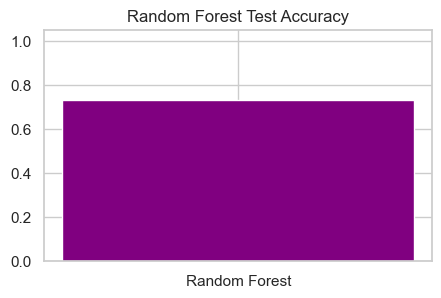

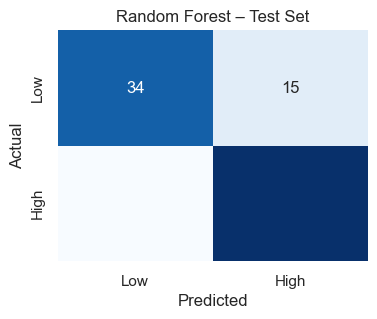

In [15]:
# -------------------------
# TASK 4: Random Forest (Bagging)
# -------------------------

print("\nTASK 4: Random Forest (Bagging)")

class RandomForest:
    """
    A simple Random Forest (bagging) classifier built on top of our custom
    decision tree implementation. Each tree sees a bootstrap sample and a
    random subset of features, which helps reduce variance.
    """
    def __init__(self, n_trees=30, max_depth=8, min_samples_split=5,
                 max_features=None, seed=RANDOM_SEED):
        self.n_trees = n_trees
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.max_features = max_features   # if None: sqrt(#features)
        self.seed = seed
        self.trees = []     # store tuples of (tree, subset_of_features)

    # Bootstrap sampling for bagging
    def _bootstrap(self, X_df, y_arr, idx):
        rs = np.random.RandomState(self.seed + idx)
        ids = rs.choice(len(X_df), size=len(X_df), replace=True)
        return X_df.iloc[ids].reset_index(drop=True), y_arr[ids]

    # Random feature subset selection
    def _feature_subset(self, X_df, idx):
        cols = list(X_df.columns)
        n = len(cols)

        if self.max_features is None:
            k = max(1, int(np.sqrt(n)))
        else:
            k = min(self.max_features, n)

        rs = np.random.RandomState(self.seed + idx + 1000)
        if k >= n:
            return cols
        return list(rs.choice(cols, size=k, replace=False))

    def fit(self, X_df, y_arr):
        self.trees = []
        for i in range(self.n_trees):
            Xb, yb = self._bootstrap(X_df, y_arr, i)
            subset = self._feature_subset(X_df, i)

            # Build one tree on the bootstrap sample with chosen features
            tree = build_tree(
                Xb[subset],
                yb,
                max_depth=self.max_depth,
                min_samples_split=self.min_samples_split,
                rnd_state=np.random.RandomState(self.seed + i)
            )
            self.trees.append((tree, subset))

    def predict(self, X_df):
        if len(self.trees) == 0:
            raise ValueError("Model has not been fitted.")

        # Collect predictions from every tree
        all_votes = []
        for tree, subset in self.trees:
            preds = predict(tree, X_df[subset])
            all_votes.append(preds)

        all_votes = np.array(all_votes)  # shape: (n_trees, n_samples)

        final = []
        # Majority voting
        for col in all_votes.T:
            vals, counts = np.unique(col, return_counts=True)
            max_count = counts.max()
            winners = vals[counts == max_count]
            final.append(int(winners.min()))  # deterministic tie-break: smallest label
        return np.array(final)


# ---- Train and evaluate the Random Forest ----
rf = RandomForest(
    n_trees=30,
    max_depth=8,
    min_samples_split=5,
    max_features=None,
    seed=RANDOM_SEED
)

rf.fit(X_train, y_train)
rf_pred_test = rf.predict(X_test)

metrics_rf = {
    "Test Accuracy": accuracy(y_test, rf_pred_test),
    "Precision": precision(y_test, rf_pred_test),
    "Recall": recall(y_test, rf_pred_test),
    "F1-Score": f1_score(y_test, rf_pred_test)
}

print("Random Forest performance:", metrics_rf)

# Simple visual: accuracy bar
plt.figure(figsize=(5,3))
plt.bar(["Random Forest"], [metrics_rf["Test Accuracy"]], color="purple")
plt.ylim(0,1.05)
plt.title("Random Forest Test Accuracy")
plt.show()

# Quick confusion matrix
plot_confusion_matrix(y_test, rf_pred_test, title="Random Forest – Test Set")


TASK 5: Final comparison across all models


,Model,Accuracy,Precision,Recall,F1,Total Nodes,Max Depth
0,Baseline Tree,0.67,0.673077,0.686275,0.679612,45,6.000000
1,Pre-Pruned Tree,0.65,0.653846,0.666667,0.660194,31,6.000000
2,Post-Pruned Tree,0.56,0.600000,0.411765,0.488372,27,8.000000
3,Random Forest,0.73,0.722222,0.764706,0.742857,1864,7.866667


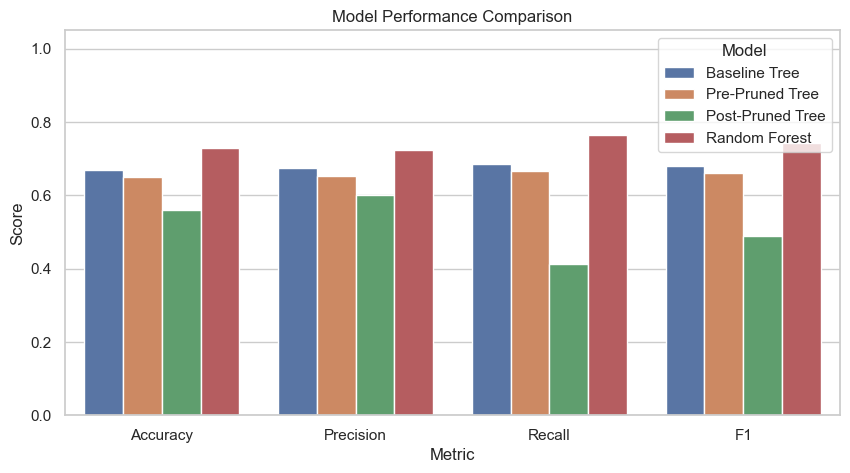


Final Summary:
Baseline Tree test accuracy: 0.67
Pre-Pruned test accuracy: 0.65  | params: (6, 20)
Post-Pruned test accuracy: 0.56 | nodes pruned: 26
Random Forest test accuracy: 0.73


In [16]:
# -------------------------
# TASK 5: Final Comparison & Summary
# -------------------------

print("\nTASK 5: Final comparison across all models")

comparison = pd.DataFrame([
    {
        "Model": "Baseline Tree",
        "Accuracy": metrics_baseline["Test Accuracy"],
        "Precision": metrics_baseline["Precision"],
        "Recall": metrics_baseline["Recall"],
        "F1": metrics_baseline["F1-Score"],
        "Total Nodes": tree_stats["Total Nodes"],
        "Max Depth": tree_stats["Max Depth"]
    },
    {
        "Model": "Pre-Pruned Tree",
        "Accuracy": metrics_pre_pruned["Test Accuracy"],
        "Precision": metrics_pre_pruned["Precision"],
        "Recall": metrics_pre_pruned["Recall"],
        "F1": metrics_pre_pruned["F1-Score"],
        "Total Nodes": pre_pruned_stats["Total Nodes"],
        "Max Depth": pre_pruned_stats["Max Depth"]
    },
    {
        "Model": "Post-Pruned Tree",
        "Accuracy": metrics_post_pruned["Test Accuracy"],
        "Precision": metrics_post_pruned["Precision"],
        "Recall": metrics_post_pruned["Recall"],
        "F1": metrics_post_pruned["F1-Score"],
        "Total Nodes": post_pruned_stats["Total Nodes"],
        "Max Depth": post_pruned_stats["Max Depth"]
    },
    {
        "Model": "Random Forest",
        "Accuracy": metrics_rf["Test Accuracy"],
        "Precision": metrics_rf["Precision"],
        "Recall": metrics_rf["Recall"],
        "F1": metrics_rf["F1-Score"],
        "Total Nodes": sum(count_nodes(t) for t, _ in rf.trees),
        "Max Depth": float(np.mean([tree_max_depth(t) for t, _ in rf.trees]))
    }
])

display(comparison)

# Simple grouped bar chart for performance metrics
cmp_long = comparison.melt(
    id_vars=["Model", "Total Nodes", "Max Depth"],
    value_vars=["Accuracy", "Precision", "Recall", "F1"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10,5))
sns.barplot(data=cmp_long, x="Metric", y="Score", hue="Model")
plt.ylim(0, 1.05)
plt.title("Model Performance Comparison")
plt.show()

# Final overview printout
print("\nFinal Summary:")
print("Baseline Tree test accuracy:", metrics_baseline["Test Accuracy"])
print("Pre-Pruned test accuracy:", metrics_pre_pruned["Test Accuracy"], " | params:", (best_max_d, best_min_s))
print("Post-Pruned test accuracy:", metrics_post_pruned["Test Accuracy"], "| nodes pruned:", pruned_count)
print("Random Forest test accuracy:", metrics_rf["Test Accuracy"])